A Portuguese bank called its customers to sell a term deposit (a savings product where you lock money away for a fixed time in exchange for interest). Each row is one customer who got a call, and y records whether they bought it.

The bank’s problem is that only about 11% said yes. That means roughly 9 out of 10 calls were wasted time for the call center. If the bank could predict who is likely to say yes, it could call fewer people and still get most of the sales. 

Part 1: Business questions to answer:
1. Who should we call?
    - Which customer profiles (age, job, education, loans) convert the most?
    - Can we give each customer a score from 0 to 100% and call the highest-scoring ones first?
2. When and how should we call?
    - Do some months convert better than others?
    - Does mobile work better than landline?
3. How many times should we call?
    - Does calling the same person again and again help, or does it annoy them?
    - At what point should we stop calling?
4. Do past customers matter?
    - Are people who said yes in previous campaign more likely to say yes again?
5. Do people save more when interest rates are high or when the economy is uncertainly? 
   (euribor3m, cons.conf.idx)


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import sklearn as sk

In [2]:
# Load the dataset
df = pd.read_csv('_ds/bank_marketing.csv', sep=';')

In [3]:
# Display the first few rows of the dataset
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [4]:
# Display the summary information of the dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

In [5]:
#1. which groups of customers convert the most? We answer this by exploring the data.

#turn yes/no into 1/0
df['converted'] = (df['y'] == 'yes').astype(int)


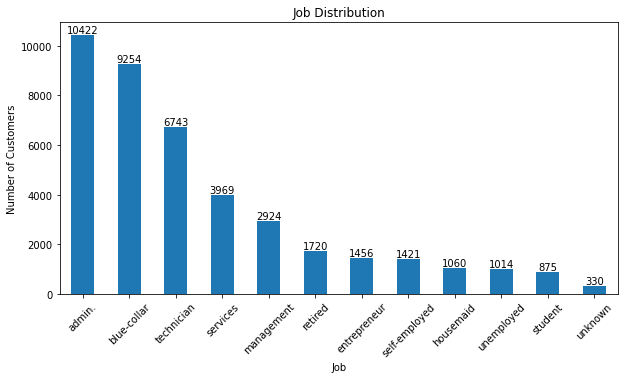

In [6]:
ax = df['job'].value_counts().plot(kind='bar', title='Job Distribution', figsize=(10, 5), rot=45)
ax.set_xlabel('Job')
ax.set_ylabel('Number of Customers')
ax.bar_label(ax.containers[0])
plt.show()

In [7]:
#df[['converted', 'y']].head()
#df.groupby('job').agg({'converted': ['mean', 'count']}).sort_values(by=('converted', 'mean'), ascending=False)
#df['job'].value_counts().plot(kind='bar', title='Job Distribution', figsize=(10, 5))
df.groupby('job').agg({'converted': ['mean', 'count']}).sort_values(by=('converted', 'mean'), ascending=False)

converted       
                   mean  count
job                           
student        0.314286    875
retired        0.252326   1720
unemployed     0.142012   1014
admin.         0.129726  10422
management     0.112175   2924
unknown        0.112121    330
technician     0.108260   6743
self-employed  0.104856   1421
housemaid      0.100000   1060
entrepreneur   0.085165   1456
services       0.081381   3969
blue-collar    0.068943   9254

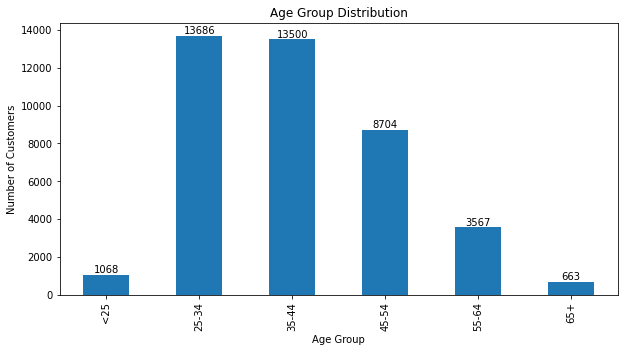

In [8]:
df['age_group'] = pd.cut(df['age'], bins=[0, 25, 35, 45, 55, 65, 100],
                         labels=['<25', '25-34','35-44', '45-54', '55-64', '65+'], right=False)

ax = df['age_group'].value_counts().sort_index().plot(kind='bar', title='Age Group Distribution', figsize=(10, 5))
ax.set_xlabel('Age Group')
ax.set_ylabel('Number of Customers')
ax.bar_label(ax.containers[0])
plt.show()

In [9]:
df.groupby('age_group').agg({'converted': ['mean', 'count']}).sort_values(by=('converted', 'mean'), ascending=False)

converted       
               mean  count
age_group                 
65+        0.472097    663
<25        0.239700   1068
55-64      0.135688   3567
25-34      0.121730  13686
35-44      0.086519  13500
45-54      0.086512   8704

In [ ]:
df.groupby('education').agg({'converted': ['mean', 'count']}).sort_values(by=('converted', 'mean'), ascending=False)

# After seeing the data, we cannot conclude that education is a strong predictor of conversion alone. 
# However, inside the model, it may be a strong predictor when combined with other features. 
# The model looks at all features together and gives each one the weight it deserves.

converted       
                         mean  count
education                           
illiterate           0.222222     18
unknown              0.145003   1731
university.degree    0.137245  12168
professional.course  0.113485   5243
high.school          0.108355   9515
basic.4y             0.102490   4176
basic.6y             0.082024   2292
basic.9y             0.078246   6045

In [11]:
df['converted_loan'] = (df['loan'] == 'yes').astype(int)
df.groupby('converted_loan').agg({'converted': ['mean', 'count']}).sort_values(by=('converted', 'mean'), ascending=False)

converted       
                    mean  count
converted_loan                 
0               0.113251  34940
1               0.109315   6248

In [12]:
result = df.groupby(['age_group', 'job']).agg({'converted': ['mean', 'count']}).sort_values(by=('converted', 'mean'), ascending=False)
result = result.loc[[('<25', 'student'), ('65+', 'retired')]]
result

converted      
                       mean count
age_group job                    
<25       student  0.378307   378
65+       retired  0.471429   560

To answer the question 1

Which 2 jobs convert the most? Is that what you expected?
    - Student and retired

Which age groups convert best? Do you see a pattern?
    - <25, 65+ years old

Does having a loan make a big difference?
    - not really

If we could call only one type of customer, who would you pick, and why?
    - Retired 65+ yo has 47% of conversion rate.

PART 2: build a model that looks at all 20 features at once and gives each customer a score.

In [36]:
#reload the dataset
df = pd.read_csv('_ds/bank_marketing.csv', sep=';')

#the answer we want to predict (1=yes, 0=no)
y = (df['y']== 'yes').astype(int)

#drop the columns the model can use to predict the answer
X = df.drop(columns=['y', 'duration'])

In [37]:
#split the dataset into training and testing sets
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print(X_train.shape, X_test.shape)

(32950, 19) (8238, 19)


In [38]:
#translate categorical variables into numerical variables

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

text_cols = X.select_dtypes(exclude='number').columns
number_cols = X.select_dtypes(include='number').columns

prep = ColumnTransformer([
    ('text', OneHotEncoder(handle_unknown='ignore'), text_cols),
    ('numbers', StandardScaler(), number_cols)])

In [39]:
#build and train the model
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

model = Pipeline([
    ('prep', prep),
    ('logreg', LogisticRegression(max_iter=1000))])

model.fit(X_train, y_train)

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('text',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  Index(['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact',
       'month', 'day_of_week', 'poutcome'],
      dtype='object')),
                                                 ('numbers', StandardScaler(),
                                                  Index(['age', 'campaign', 'pdays', 'previous', 'emp.var.rate',
       'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed'],
      dtype='object'))])),
                ('logreg', LogisticRegression(max_iter=1000))])

In [40]:
#give every test customer a score
scores = model.predict_proba(X_test)[:, 1]

results = X_test.copy()
results['score'] = scores
results['actually_said_yes'] = y_test

results.sort_values('score', ascending=False)[['age', 'job', 'poutcome', 'score', 'actually_said_yes']].head(10)


,age,job,poutcome,score,actually_said_yes
40450,92,retired,success,0.900405,1
39348,78,retired,success,0.890967,1
39340,30,student,success,0.889642,1
40469,92,retired,success,0.887029,1
39180,64,retired,success,0.886229,0
40276,68,retired,success,0.885019,1
39153,21,student,success,0.884256,1
40368,27,student,success,0.883642,1
39221,34,admin.,success,0.874110,1
40413,59,retired,success,0.866210,1


In [41]:
top10 = results.sort_values('score', ascending=False).head(len(results) // 10)

print('Customers called:', len(top10))
print('Conversion rate:', top10['actually_said_yes'].mean())
print('Yes found:', top10['actually_said_yes'].sum(), 'out of', results['actually_said_yes'].sum())

Customers called: 823
Conversion rate: 0.5042527339003645
Yes found: 415 out of 928


To answer questions in part 2:
1. Calling at random converts at 11.3%. The model’s top 10% converts at 50.4%. How many times better is that?
- About 4.5x

2. By calling only 10% of customers, what share of all 928 yes’s do we find?
- 44.7% (415/928)

3. In your top 10 rows from Step 5, which column keeps showing the same value? Does it match what you found in Part 1?
- poutcome = "success"

4. Business question: if you were the call-center manager, how would you use this list?
- Instead of calling every customer, we’ll call only the top 30% of the model’s list. 
This group converts at 27%, compared with 11% when calling at random, and it reaches 72% of all customers who would say yes. 
We start with previous buyers, who convert at 65%. 
This cuts the number of calls by 70% while keeping almost three-quarters of the sales, saving call-center time and budget.